# Level 1 Task 4: Sentiment Analysis
**Oasis Infobyte Data Analytics Internship**

### Project Overview
This notebook applies Natural Language Processing (NLP) to analyze the sentiment of social media text. Using the NLTK library and the VADER lexicon, we calculate sentiment polarity scores for tweets and categorize them as positive, negative, or neutral.

In [3]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Initialize the analyzer
nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# 1. Load the dataset correctly (letting pandas find the existing headers)
df = pd.read_csv('train.csv', encoding='latin-1')

# 2. Drop any rows where the 'text' column is completely missing
df = df.dropna(subset=['text'])

# 3. Define a function to extract the VADER 'compound' score (-1 to 1)
def get_vader_score(text):
    return sia.polarity_scores(str(text))['compound']

# 4. Define a function to categorize that score
def categorize_sentiment(score):
    if score >= 0.05:
        return 'positive'
    elif score <= -0.05:
        return 'negative'
    else:
        return 'neutral'

# 5. Apply the functions to our dataset
print("Analyzing sentiment... (this might take a few seconds)")
df['vader_score'] = df['text'].apply(get_vader_score)
df['vader_prediction'] = df['vader_score'].apply(categorize_sentiment)

# 6. Compare VADER's prediction with the actual 'sentiment' column!
display(df[['text', 'sentiment', 'vader_prediction', 'vader_score']].head(10))

Analyzing sentiment... (this might take a few seconds)


,text,sentiment,vader_prediction,vader_score
0,"I`d have responded, if I were going",neutral,neutral,0.0000
1,Sooo SAD I will miss you here in San Diego!!!,negative,negative,-0.7437
2,my boss is bullying me...,negative,negative,-0.5994
3,what interview! leave me alone,negative,negative,-0.3595
4,"Sons of ****, why couldn`t they put them on t...",negative,neutral,0.0000
5,http://www.dothebouncy.com/smf - some shameles...,neutral,positive,0.4215
6,2am feedings for the baby are fun when he is a...,positive,positive,0.7506
7,Soooo high,neutral,neutral,0.0000
8,Both of you,neutral,neutral,0.0000
9,Journey!? Wow... u just became cooler. hehe....,positive,neutral,0.0000


VADER Sentiment Accuracy: 63.13%



C:\Users\dp185\AppData\Local\Temp\ipykernel_39476\2375913460.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', order=['positive', 'neutral', 'negative'], palette='mako', ax=axes[0])
C:\Users\dp185\AppData\Local\Temp\ipykernel_39476\2375913460.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='vader_prediction', order=['positive', 'neutral', 'negative'], palette='mako', ax=axes[1])


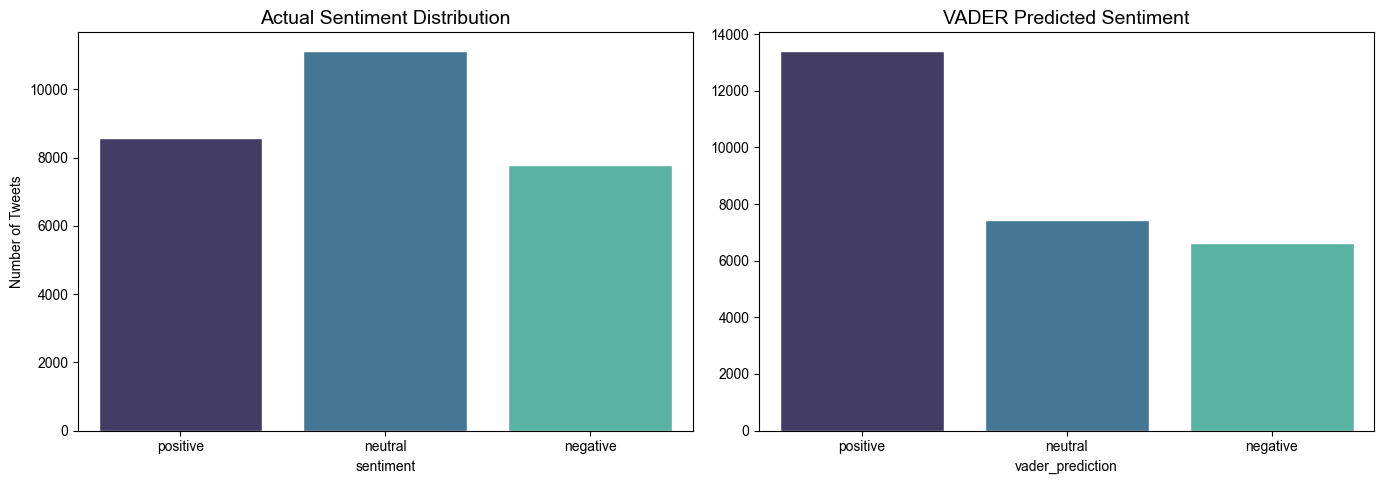

In [4]:
# 1. Calculate overall accuracy
accuracy = (df['sentiment'] == df['vader_prediction']).mean() * 100
print(f"VADER Sentiment Accuracy: {accuracy:.2f}%\n")

# 2. Visualize Actual vs Predicted Sentiments
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

# Chart 1: Actual Ground Truth
sns.countplot(data=df, x='sentiment', order=['positive', 'neutral', 'negative'], palette='mako', ax=axes[0])
axes[0].set_title('Actual Sentiment Distribution', fontsize=14)
axes[0].set_ylabel('Number of Tweets')

# Chart 2: VADER Predictions
sns.countplot(data=df, x='vader_prediction', order=['positive', 'neutral', 'negative'], palette='mako', ax=axes[1])
axes[1].set_title('VADER Predicted Sentiment', fontsize=14)
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### Conclusion & Limitations
* **Accuracy:** The out-of-the-box VADER model achieved a 63.13% accuracy on this dataset.
* **Model Bias:** Visualization reveals that VADER leans heavily toward classifying tweets as positive, whereas the ground-truth data contains a much higher volume of neutral tweets.
* **Lexicon Limitations:** As a rule-based lexicon, VADER struggles with implicit context, sarcasm, and heavily censored profanity (e.g., asterisks replacing letters), which often results in inaccurate neutral scores.